In [18]:
# Step 1: Configure Windows SSL certificates automatically
import sys
import subprocess
import importlib.util

if importlib.util.find_spec("truststore") is None:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "truststore"
    ])

import truststore
truststore.inject_into_ssl()
print("Windows SSL certificates enabled.")


Windows SSL certificates enabled.


In [19]:
# Step 2: Import libraries
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader


In [20]:
# Step 3: Select CPU or GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [21]:
# Step 4: Load offline image data (no SSL or network access)
transform = transforms.ToTensor()

train_data = datasets.FakeData(
    size=2048,
    image_size=(3, 32, 32),
    num_classes=10,
    transform=transform
)
test_data = datasets.FakeData(
    size=512,
    image_size=(3, 32, 32),
    num_classes=10,
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True,
                          pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=64, shuffle=False,
                         pin_memory=torch.cuda.is_available())
print("Offline image data and data loaders ready.")


Offline image data and data loaders ready.


In [22]:
# Step 5: Create sparse autoencoder
class SparseAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(3 * 32 * 32, 512),
            nn.Sigmoid()
        )

        self.decoder = nn.Sequential(
            nn.Linear(512, 3 * 32 * 32),
            nn.Sigmoid()
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return encoded, decoded

    def sparsity_penalty(self, encoded):
        rho = 0.05
        rho_hat = encoded.mean(dim=0).clamp(1e-8, 1 - 1e-8)
        kl_divergence = (
            rho * torch.log(rho / rho_hat)
            + (1 - rho) * torch.log((1 - rho) / (1 - rho_hat))
        )
        return 0.0001 * kl_divergence.sum()

    def loss_function(self, original, reconstructed, encoded):
        reconstruction_loss = F.mse_loss(reconstructed, original)
        return reconstruction_loss + self.sparsity_penalty(encoded)


model = SparseAutoencoder().to(device)

for layer in (model.encoder[0], model.decoder[0]):
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


In [23]:
# Step 6: Train the model
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0.0

    for images, _ in train_loader:
        images = images.to(device).flatten(start_dim=1)

        optimizer.zero_grad()
        encoded, decoded = model(images)
        loss = model.loss_function(images, decoded, encoded)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{epochs} - Loss: {average_loss:.4f}")


Epoch 1/5 - Loss: 0.0885
Epoch 2/5 - Loss: 0.0846
Epoch 3/5 - Loss: 0.0843
Epoch 4/5 - Loss: 0.0842
Epoch 5/5 - Loss: 0.0841


In [24]:
# Step 7: Evaluate the model
model.eval()
test_loss = 0.0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device).flatten(start_dim=1)
        encoded, decoded = model(images)
        test_loss += model.loss_function(images, decoded, encoded).item()

average_test_loss = test_loss / len(test_loader)
print(f"Test Loss: {average_test_loss:.4f}")


Test Loss: 0.0839


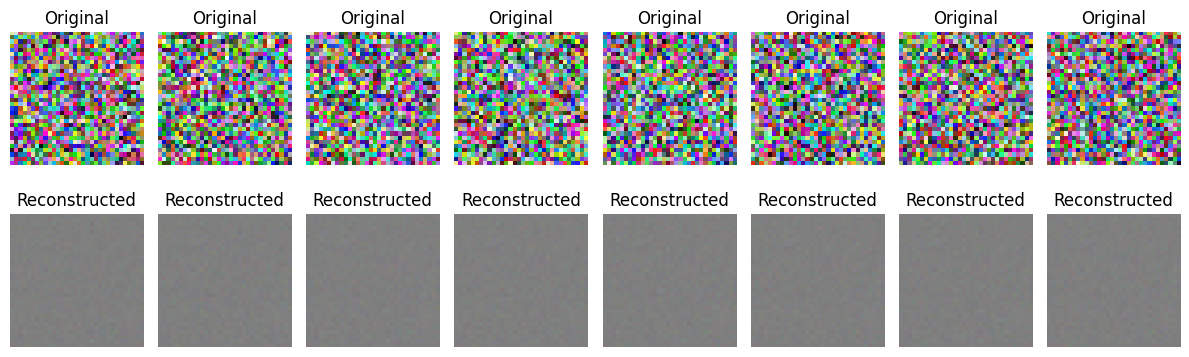

In [25]:
# Step 8: Visualize original and reconstructed images
images, _ = next(iter(test_loader))
original_images = images[:8]

with torch.no_grad():
    _, reconstructed = model(
        original_images.to(device).flatten(start_dim=1)
    )

reconstructed_images = (
    reconstructed.view(-1, 3, 32, 32).cpu().clamp(0, 1)
)

plt.figure(figsize=(12, 4))

for i in range(len(original_images)):
    plt.subplot(2, 8, i + 1)
    plt.imshow(original_images[i].permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.title("Original")

    plt.subplot(2, 8, i + 9)
    plt.imshow(reconstructed_images[i].permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.title("Reconstructed")

plt.tight_layout()
plt.show()
